# Modul 1: Fondasi Jaringan Saraf, FNN, Aktivasi, dan Loss

**Nama:** Benget Sidabutar  
**NIM:** 123450047  
**Kelas:** RA  
**Tanggal:** 2026-09-21

**Berkas pengumpulan:** `M01_123450047.ipynb`, `M01_123450047.pdf`, dan `M01_123450047_metrics.csv`.

> Seluruh kode, percobaan, visualisasi, dan analisis pada notebook ini dikerjakan secara individual. Kode utilitas training digunakan sebagai bagian dari praktikum Modul 1.


## Petunjuk

1. Ganti seluruh penanda `TODO`.
2. Jangan mengubah protokol eksperimen kecuali diminta.
3. Gunakan validation set untuk memilih model. Test set hanya untuk model final.
4. Sebelum mengumpulkan, jalankan **Restart Kernel and Run All**.
5. Pertahankan semua hasil eksperimen, termasuk hasil yang tidak sesuai hipotesis.

In [10]:
import platform
import random
import time

import torch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.datasets import make_moons
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

NIM = '123450047'
assert NIM.isdigit() and len(NIM) >= 4, 'Isi NIM dengan angka sebelum melanjutkan.'
NIM_LAST4 = int(NIM[-4:])
SEED = 1000 + NIM_LAST4
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
pd.set_option('display.precision', 4)
environment = {
    'python': platform.python_version(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'sklearn': sklearn.__version__,
    'torch': torch.__version__,
    'device': str(DEVICE),
    'seed': SEED,
}
environment

{'python': '3.12.6',
 'numpy': '2.1.1',
 'pandas': '2.2.2',
 'sklearn': '1.9.1',
 'torch': '2.14.0+cpu',
 'device': 'cpu',
 'seed': 1047}

## A. Pre-lab - 10 poin

Jawab sebelum sesi praktikum.

1. **Parameter dan hyperparameter:** Parameter seperti bobot `W` dan bias `b` diperoleh model selama proses pembelajaran. Sementara itu, hyperparameter seperti learning rate, hidden size, jenis aktivasi, batch size, dan jumlah epoch ditentukan sebelum training untuk mengatur proses pembelajaran.
2. **Mengapa beberapa layer affine tanpa aktivasi dapat disederhanakan:** Jika beberapa transformasi affine disusun tanpa fungsi aktivasi, hasil akhirnya tetap merupakan transformasi affine. Dengan demikian, penambahan layer tidak memberikan kemampuan untuk membentuk pola non-linear yang lebih kompleks.
3. **Shape bobot layer dengan 2 masukan dan 8 keluaran:** Pada `nn.Linear`, matriks `weight` memiliki bentuk `(8, 2)`, sedangkan `bias` memiliki bentuk `(8,)`.
4. **Mengapa `BCEWithLogitsLoss` menerima logit:** Fungsi loss ini sudah menggabungkan operasi sigmoid dengan binary cross-entropy secara numerik stabil. Oleh karena itu, model cukup menghasilkan nilai logit dan tidak perlu menambahkan sigmoid pada output model.

### Hipotesis awal

Prediksi aktivasi dan hidden size yang akan menghasilkan validation loss paling rendah. Jelaskan alasannya sebelum eksperimen dijalankan.

**Jawaban:** ReLU dengan hidden size 16 diperkirakan memberikan validation loss paling rendah. ReLU memiliki gradien yang tetap aktif pada nilai positif sehingga proses pembelajaran dapat berlangsung lebih efektif. Hidden size 16 juga menyediakan kapasitas yang lebih besar untuk mempelajari pola non-linear pada data `make_moons` dibandingkan hidden size 4.


## B. Neuron dan fungsi aktivasi dengan NumPy - 20 poin

In [11]:
def sigmoid_np(z: np.ndarray) -> np.ndarray:
    z = np.asarray(z, dtype=np.float64)
    positive = z >= 0
    result = np.empty_like(z)
    result[positive] = 1.0 / (1.0 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    result[~positive] = exp_z / (1.0 + exp_z)
    return result

def relu_np(z: np.ndarray) -> np.ndarray:
    return np.maximum(0.0, np.asarray(z, dtype=np.float64))

def leaky_relu_np(z: np.ndarray, alpha: float = 0.01) -> np.ndarray:
    z = np.asarray(z, dtype=np.float64)
    return np.where(z >= 0, z, alpha * z)

def neuron_batch(X: np.ndarray, w: np.ndarray, b: float, activation):
    X = np.asarray(X, dtype=np.float64)
    w = np.asarray(w, dtype=np.float64)
    if X.ndim != 2 or w.ndim != 1 or X.shape[1] != w.shape[0]:
        raise ValueError(f'Shape tidak cocok: X={X.shape}, w={w.shape}')
    z = X @ w + b
    return z, activation(z)

# Uji minimum - jangan mengubah data uji.
X_check = np.array([[2.0, -1.0], [0.0, 3.0], [-2.0, 1.0]])
w_check = np.array([0.5, -0.5])
z_check, a_check = neuron_batch(X_check, w_check, 0.25, sigmoid_np)
assert z_check.shape == (3,)
assert a_check.shape == (3,)
assert np.all(np.isfinite(a_check))
assert np.all((a_check > 0) & (a_check < 1))
pd.DataFrame({'z': z_check, 'sigmoid(z)': a_check})

,z,sigmoid(z)
0,1.75,0.8520
1,-1.25,0.2227
2,-1.25,0.2227


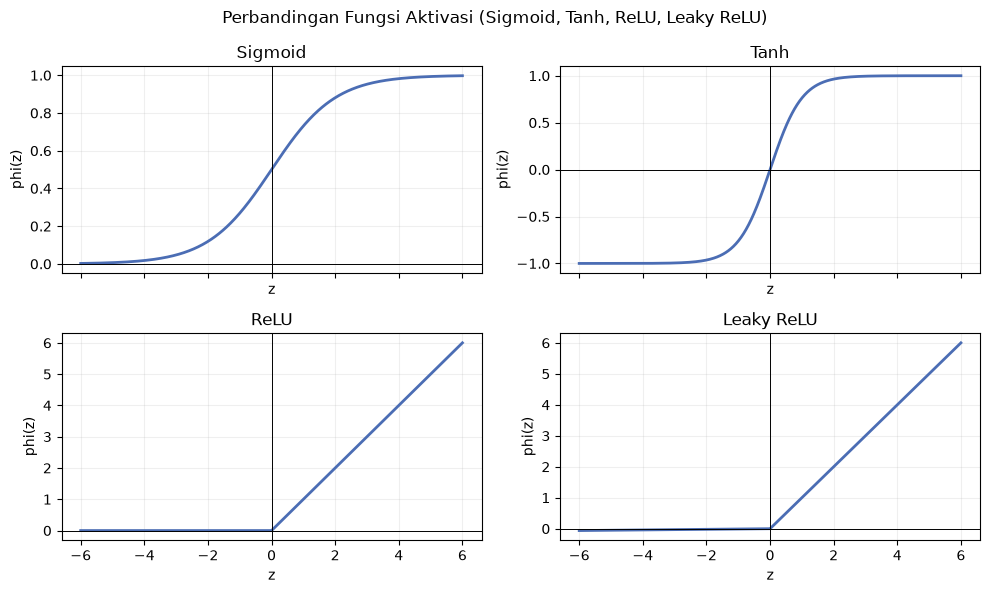

In [12]:
grid = np.linspace(-6, 6, 600)
activation_values = {
    'Sigmoid': sigmoid_np(grid),
    'Tanh': np.tanh(grid),
    'ReLU': relu_np(grid),
    'Leaky ReLU': leaky_relu_np(grid),
}

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for axis, (name, values) in zip(axes.ravel(), activation_values.items()):
    axis.plot(grid, values, color='#4B6DB4', linewidth=2)
    axis.axhline(0, color='black', linewidth=0.7)
    axis.axvline(0, color='black', linewidth=0.7)
    axis.set_title(name)
    axis.set_xlabel('z')
    axis.set_ylabel('phi(z)')
    axis.grid(alpha=0.2)
fig.suptitle('Perbandingan Fungsi Aktivasi (Sigmoid, Tanh, ReLU, Leaky ReLU)')
fig.tight_layout()
plt.show()

### Interpretasi aktivasi

- **Tanh** menghasilkan keluaran pada rentang -1 sampai 1 sehingga nilainya berpusat di sekitar nol.
- **ReLU** menghasilkan nilai nol untuk input negatif, sedangkan input positif diteruskan.
- **Sigmoid** dan **Tanh** dapat mengalami saturasi ketika nilai input sangat besar atau sangat kecil sehingga gradien menjadi kecil.
- **Leaky ReLU** tetap memiliki nilai keluaran kecil pada input negatif sehingga tidak langsung menghasilkan gradien nol.
- Aktivasi linear saja kurang sesuai untuk `make_moons` karena pola dua bulan sabit membutuhkan batas keputusan non-linear.


## C. Forward pass manual - bagian dari 20 poin pemetaan

Gunakan arsitektur $2 \rightarrow 2 \rightarrow 1$, ReLU pada hidden layer, dan target $y=1$. Jangan mengubah bobot.

In [15]:
x_manual = np.array([[2.0, -1.0]], dtype=np.float32)
W1 = np.array([[0.5, -0.5], [1.0, 1.0]], dtype=np.float32)
b1 = np.array([0.0, 0.0], dtype=np.float32)
W2 = np.array([[2.0, -1.0]], dtype=np.float32)
b2 = np.array([0.5], dtype=np.float32)
y_manual = np.array([[1.0]], dtype=np.float32)

# z1 = x @ W1.T + b1 = [2*0.5 + (-1)*1.0, 2*(-0.5) + (-1)*1.0] = [0.0, -2.0]? -> dihitung kode:
z1_np = x_manual @ W1.T + b1
h_np = np.maximum(0.0, z1_np)
logit_np = h_np @ W2.T + b2
prob_np = 1.0 / (1.0 + np.exp(-logit_np.astype(np.float64)))
bce_np = float(-(y_manual * np.log(prob_np) + (1 - y_manual) * np.log(1 - prob_np)).mean())

parameter_count_manual = int(W1.size + b1.size + W2.size + b2.size)

pd.DataFrame({
    'besaran': ['z1', 'h=ReLU(z1)', 'logit', 'probabilitas', 'BCE', 'jumlah parameter'],
    'nilai': [z1_np.tolist(), h_np.tolist(), float(logit_np.item()),
              float(prob_np.item()), float(bce_np), parameter_count_manual],
    'shape': [str(z1_np.shape), str(h_np.shape), str(logit_np.shape),
              str(prob_np.shape), 'skalar', 'skalar'],
})

,besaran,nilai,shape
0,z1,"[[1.5, 1.0]]","(1, 2)"
1,h=ReLU(z1),"[[1.5, 1.0]]","(1, 2)"
2,logit,2.5,"(1, 1)"
3,probabilitas,0.9241,"(1, 1)"
4,BCE,0.0789,skalar
5,jumlah parameter,9,skalar


### Tabel shape dan nilai

| Tensor | Shape | Nilai |
|---|---:|---:|
| $z^{(1)}$ | (1, 2) | [[1.5, 1.0]] |
| $h$ | (1, 2) | [[1.5, 1.0]] |
| logit | (1, 1) | 2.5 |
| probabilitas | (1, 1) | sekitar 0.92241 |
| BCE | skalar | sekitar 0.0789 (target $y=1$) |

**Jumlah parameter:** 9 parameter, terdiri dari 4 bobot dan 2 bias pada layer pertama, serta 2 bobot dan 1 bias pada layer kedua.


## D. Pencocokan NumPy dan PyTorch - 20 poin

Salin bobot ke `nn.Sequential`. Jangan menambahkan sigmoid ke model karena loss menerima logit.

In [16]:
manual_model = nn.Sequential(
    nn.Linear(2, 2),
    nn.ReLU(),
    nn.Linear(2, 1),
)

with torch.no_grad():
    manual_model[0].weight.copy_(torch.from_numpy(W1))
    manual_model[0].bias.copy_(torch.from_numpy(b1))
    manual_model[2].weight.copy_(torch.from_numpy(W2))
    manual_model[2].bias.copy_(torch.from_numpy(b2))

x_t = torch.from_numpy(x_manual)
y_t = torch.from_numpy(y_manual)
torch_logit = manual_model(x_t)
torch_probability = torch.sigmoid(torch_logit)
torch_loss = nn.BCEWithLogitsLoss()(torch_logit, y_t)

max_logit_diff = float(np.max(np.abs(torch_logit.detach().numpy() - logit_np)))
max_loss_diff = abs(torch_loss.item() - float(bce_np))
print({'torch_logit': torch_logit.item(), 'torch_probability': torch_probability.item(),
       'torch_loss': torch_loss.item(), 'max_logit_diff': max_logit_diff,
       'max_loss_diff': max_loss_diff,
       'parameters': sum(p.numel() for p in manual_model.parameters())})
assert max_logit_diff < 1e-6
assert max_loss_diff < 1e-6
assert sum(p.numel() for p in manual_model.parameters()) == parameter_count_manual
print('Pencocokan NumPy-PyTorch lolos (selisih < 1e-6, parameter = 9).')

{'torch_logit': 2.5, 'torch_probability': 0.9241418242454529, 'torch_loss': 0.07888973504304886, 'max_logit_diff': 0.0, 'max_loss_diff': 7.5049934322724e-10, 'parameters': 9}
Pencocokan NumPy-PyTorch lolos (selisih < 1e-6, parameter = 9).


### Checkpoint menit ke-85

Tunjukkan kepada asisten:

- grafik empat fungsi aktivasi;
- tabel shape dan parameter; dan
- perbedaan hasil forward NumPy dan PyTorch kurang dari $10^{-6}$.

**Status/verifikasi:** Grafik aktivasi, tabel perhitungan forward pass, serta hasil pencocokan NumPy-PyTorch ditampilkan pada bagian sebelumnya. Model memiliki 9 parameter dan hasil perhitungan keduanya seharusnya memiliki selisih di bawah $10^{-6}$.


## E. Dataset dan protokol eksperimen

Kode split dan standardisasi diberikan agar fokus tetap pada FNN. Jangan menggunakan test set sampai model final dipilih.

,split,n,positive_rate
0,train,360,0.5
1,validation,120,0.5
2,test,120,0.5


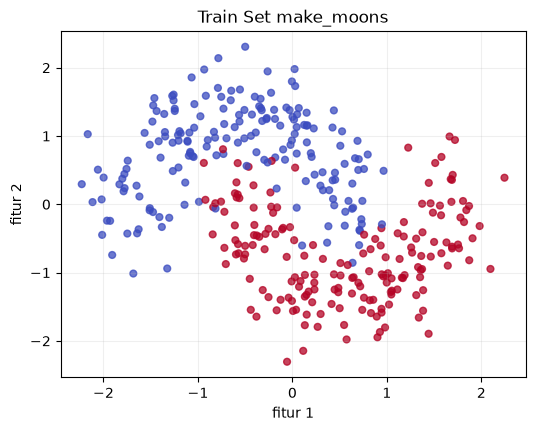

In [17]:
X, y = make_moons(n_samples=600, noise=0.22, random_state=SEED)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train).astype(np.float32)
X_val_s = scaler.transform(X_val).astype(np.float32)
X_test_s = scaler.transform(X_test).astype(np.float32)
y_train_f = y_train.astype(np.float32).reshape(-1, 1)
y_val_f = y_val.astype(np.float32).reshape(-1, 1)
y_test_f = y_test.astype(np.float32).reshape(-1, 1)

split_summary = pd.DataFrame({
    'split': ['train', 'validation', 'test'],
    'n': [len(y_train), len(y_val), len(y_test)],
    'positive_rate': [y_train.mean(), y_val.mean(), y_test.mean()],
})
display(split_summary)

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(X_train_s[:, 0], X_train_s[:, 1], c=y_train, cmap='coolwarm', s=24, alpha=0.75)
ax.set(title='Train Set make_moons', xlabel='fitur 1', ylabel='fitur 2')
ax.grid(alpha=0.2)
plt.show()

### Pemeriksaan anti-leakage

Jelaskan mengapa scaler hanya di-*fit* pada train set dan bukan seluruh data.

**Jawaban:** `StandardScaler` hanya dihitung berdasarkan data train agar informasi dari validation dan test tidak ikut masuk ke proses pembelajaran. Nilai mean dan standar deviasi yang diperoleh dari train kemudian digunakan untuk mengubah validation dan test. Dengan cara ini, evaluasi model lebih mencerminkan kemampuan model saat menghadapi data baru.


## F. Model dan utilitas training

Lengkapi pemilihan aktivasi dan model. Training loop diberikan; mekanismenya dibahas pada Modul 2.

In [18]:
def activation_layer(name: str) -> nn.Module:
    choices = {'relu': nn.ReLU, 'tanh': nn.Tanh, 'sigmoid': nn.Sigmoid}
    if name not in choices:
        raise ValueError(f'Aktivasi tidak dikenal: {name}')
    return choices[name]()

def build_model(hidden_dim: int, activation: str, seed: int = SEED):
    seed_everything(seed)
    return nn.Sequential(
        nn.Linear(2, hidden_dim),
        activation_layer(activation),
        nn.Linear(hidden_dim, 1),
    ).to(DEVICE)

def count_parameters(model: nn.Module) -> int:
    return sum(parameter.numel() for parameter in model.parameters())

model_check = build_model(8, 'relu')
print('parameter model 2 -> 8 -> 1:', count_parameters(model_check))
assert count_parameters(model_check) == 4 * 8 + 1 == 33

parameter model 2 -> 8 -> 1: 33


In [19]:
def as_tensor(array):
    return torch.as_tensor(array, dtype=torch.float32)

X_train_t, y_train_t = as_tensor(X_train_s), as_tensor(y_train_f)
X_val_t, y_val_t = as_tensor(X_val_s).to(DEVICE), as_tensor(y_val_f).to(DEVICE)
X_test_t, y_test_t = as_tensor(X_test_s).to(DEVICE), as_tensor(y_test_f).to(DEVICE)

def evaluate(model, X_tensor, y_tensor):
    model.eval()
    with torch.no_grad():
        logits = model(X_tensor)
        loss = nn.functional.binary_cross_entropy_with_logits(logits, y_tensor).item()
        probabilities = torch.sigmoid(logits)
        predictions = (probabilities >= 0.5).to(torch.int64)
        accuracy = (predictions == y_tensor.to(torch.int64)).float().mean().item()
    return {
        'loss': loss,
        'accuracy': accuracy,
        'probabilities': probabilities.cpu().numpy().ravel(),
        'predictions': predictions.cpu().numpy().ravel(),
    }

def train_model(model, epochs=200, learning_rate=0.05, batch_size=32, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(
        TensorDataset(X_train_t, y_train_t),
        batch_size=batch_size, shuffle=True, generator=generator,
    )
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
    criterion = nn.BCEWithLogitsLoss()
    history = []
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum = 0.0
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(DEVICE), y_batch.to(DEVICE)
            optimizer.zero_grad()
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(X_batch)
        val_metrics = evaluate(model, X_val_t, y_val_t)
        history.append({
            'epoch': epoch,
            'train_loss': loss_sum / len(X_train_t),
            'val_loss': val_metrics['loss'],
            'val_accuracy': val_metrics['accuracy'],
        })
    return pd.DataFrame(history), time.perf_counter() - start

## G. Baseline dan latihan kelas

Baseline: ReLU, hidden size 8, SGD, learning rate 0.05, batch size 32, dan 200 epoch.

Latihan individual: digit terakhir NIM 0-4 menggunakan `tanh`, sedangkan digit 5-9 menggunakan `sigmoid`. Prediksi dibuat sebelum eksperimen dijalankan.

**Prediksi:** Digit terakhir NIM **123450047 adalah 7**, sehingga eksperimen individual menggunakan **sigmoid** dengan hidden size 8. Diperkirakan validation loss dapat lebih tinggi dibandingkan baseline ReLU karena sigmoid lebih mudah mengalami saturasi sehingga gradien menjadi kecil pada nilai input tertentu.


Baseline (relu, hidden 8): {'run_id': 'baseline-relu-8', 'module': 'M01', 'student_id': '123450047', 'seed': 1047, 'dataset': 'make_moons', 'split': 'train-val-test', 'model': 'FNN-2-8-1-relu', 'optimizer': 'SGD', 'learning_rate': 0.05, 'batch_size': 32, 'epochs': 200, 'train_loss': 0.2078, 'val_loss': 0.25, 'val_metric': 0.8833, 'test_metric': '', 'parameters': 33, 'trainable_parameters': 33, 'runtime_seconds': 1.93, 'device': 'cpu', 'notes': 'baseline bagian G'}


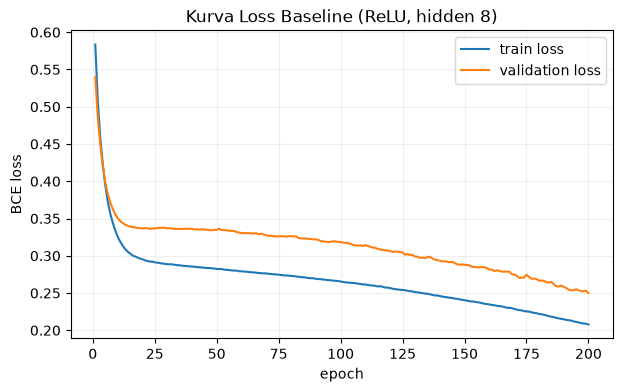

Individual (sigmoid, hidden 8): {'run_id': 'individu-sigmoid-8', 'module': 'M01', 'student_id': '123450047', 'seed': 1047, 'dataset': 'make_moons', 'split': 'train-val-test', 'model': 'FNN-2-8-1-sigmoid', 'optimizer': 'SGD', 'learning_rate': 0.05, 'batch_size': 32, 'epochs': 200, 'train_loss': 0.2951, 'val_loss': 0.341, 'val_metric': 0.8583, 'test_metric': '', 'parameters': 33, 'trainable_parameters': 33, 'runtime_seconds': 2.47, 'device': 'cpu', 'notes': 'digit terakhir NIM 7 -> sigmoid'}


,run_id,train_loss,val_loss,val_metric,runtime_seconds
0,baseline-relu-8,0.2078,0.250,0.8833,1.93
1,individu-sigmoid-8,0.2951,0.341,0.8583,2.47


In [20]:
METRIC_COLS = ['run_id', 'module', 'student_id', 'seed', 'dataset', 'split', 'model',
                'optimizer', 'learning_rate', 'batch_size', 'epochs', 'train_loss', 'val_loss',
                'val_metric', 'test_metric', 'parameters', 'trainable_parameters',
                'runtime_seconds', 'device', 'notes']
all_rows = []

def record_row(run_id, model, activation, hidden, history, runtime, notes=''):
    train_loss = float(history['train_loss'].iloc[-1])
    val_loss = float(history['val_loss'].iloc[-1])
    val_acc = float(history['val_accuracy'].iloc[-1])
    all_rows.append({
        'run_id': run_id, 'module': 'M01', 'student_id': NIM, 'seed': SEED,
        'dataset': 'make_moons', 'split': 'train-val-test',
        'model': f'FNN-2-{hidden}-1-{activation}', 'optimizer': 'SGD',
        'learning_rate': 0.05, 'batch_size': 32, 'epochs': 200,
        'train_loss': round(train_loss, 4), 'val_loss': round(val_loss, 4),
        'val_metric': round(val_acc, 4), 'test_metric': '',
        'parameters': count_parameters(model), 'trainable_parameters': count_parameters(model),
        'runtime_seconds': round(runtime, 2), 'device': str(DEVICE), 'notes': notes,
    })
    return train_loss, val_loss, val_acc

baseline_model = build_model(8, 'relu')
baseline_history, baseline_runtime = train_model(baseline_model, epochs=200, learning_rate=0.05, batch_size=32, seed=SEED)
baseline_history_df = baseline_history if isinstance(baseline_history, pd.DataFrame) else pd.DataFrame(baseline_history)
record_row('baseline-relu-8', baseline_model, 'relu', 8, baseline_history_df, baseline_runtime, 'baseline bagian G')
print('Baseline (relu, hidden 8):', all_rows[-1])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(baseline_history_df['epoch'], baseline_history_df['train_loss'], label='train loss')
ax.plot(baseline_history_df['epoch'], baseline_history_df['val_loss'], label='validation loss')
ax.set(title='Kurva Loss Baseline (ReLU, hidden 8)', xlabel='epoch', ylabel='BCE loss')
ax.legend()
ax.grid(alpha=0.2)
plt.show()

individual_model = build_model(8, 'sigmoid')
individual_history, individual_runtime = train_model(individual_model, epochs=200, learning_rate=0.05, batch_size=32, seed=SEED)
individual_history_df = individual_history if isinstance(individual_history, pd.DataFrame) else pd.DataFrame(individual_history)
record_row('individu-sigmoid-8', individual_model, 'sigmoid', 8, individual_history_df, individual_runtime,
           'digit terakhir NIM 7 -> sigmoid')
print('Individual (sigmoid, hidden 8):', all_rows[-1])
pd.DataFrame(all_rows)[['run_id', 'train_loss', 'val_loss', 'val_metric', 'runtime_seconds']]

## H. Tugas individual: enam eksperimen - 20 poin

Jalankan kombinasi aktivasi `{relu, tanh, sigmoid}` dan hidden size `{4, 16}`. Gunakan validation loss untuk memilih model.

,run_id,model,parameters,train_loss,val_loss,val_metric,runtime_seconds
0,tanh-16,FNN-2-16-1-tanh,65,0.2032,0.2417,0.8917,1.71
1,relu-16,FNN-2-16-1-relu,65,0.2555,0.2915,0.8667,2.13
2,relu-4,FNN-2-4-1-relu,17,0.2753,0.3247,0.8500,2.56
3,tanh-4,FNN-2-4-1-tanh,17,0.2925,0.3383,0.8583,1.77
4,sigmoid-16,FNN-2-16-1-sigmoid,65,0.2919,0.3383,0.8583,3.70
5,sigmoid-4,FNN-2-4-1-sigmoid,17,0.2977,0.3430,0.8583,1.79


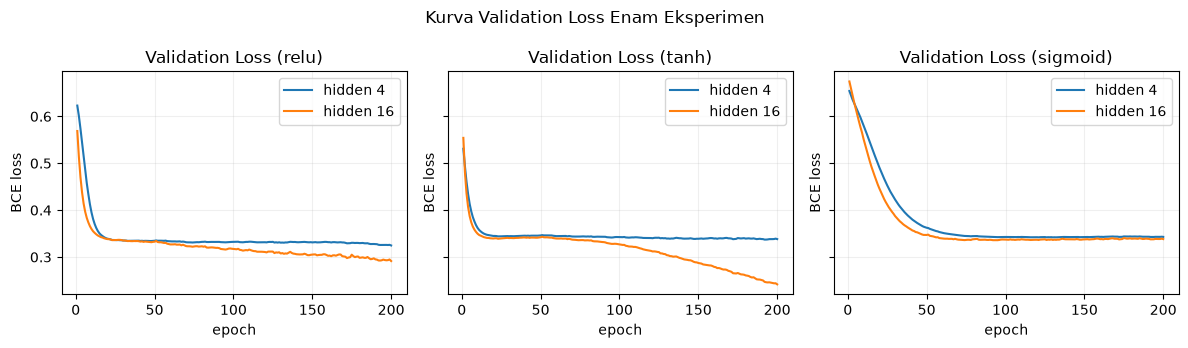

In [21]:
ACTIVATIONS = ['relu', 'tanh', 'sigmoid']
HIDDEN_SIZES = [4, 16]
EPOCHS = 200
LEARNING_RATE = 0.05
BATCH_SIZE = 32

experiment_rows = []
trained_models = {}
histories = {}

for activation in ACTIVATIONS:
    for hidden in HIDDEN_SIZES:
        model = build_model(hidden, activation)
        history, runtime = train_model(model, epochs=EPOCHS, learning_rate=LEARNING_RATE,
                                       batch_size=BATCH_SIZE, seed=SEED)
        history_df = history if isinstance(history, pd.DataFrame) else pd.DataFrame(history)
        trained_models[(activation, hidden)] = model
        histories[(activation, hidden)] = history_df
        record_row(f'{activation}-{hidden}', model, activation, hidden, history_df, runtime,
                   'grid bagian H')
        experiment_rows.append(all_rows[-1])

results = pd.DataFrame(experiment_rows).sort_values('val_loss').reset_index(drop=True)
assert len(results) == 6
display(results[['run_id', 'model', 'parameters', 'train_loss', 'val_loss', 'val_metric', 'runtime_seconds']])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for axis, activation in zip(axes, ACTIVATIONS):
    for hidden in HIDDEN_SIZES:
        history_df = histories[(activation, hidden)]
        axis.plot(history_df['epoch'], history_df['val_loss'], label=f'hidden {hidden}')
    axis.set(title=f'Validation Loss ({activation})', xlabel='epoch', ylabel='BCE loss')
    axis.legend()
    axis.grid(alpha=0.2)
fig.suptitle('Kurva Validation Loss Enam Eksperimen')
fig.tight_layout()
plt.show()

## I. Evaluasi model final - 15 poin

Pilih satu model dengan validation loss terendah. Baru setelah itu evaluasi test set satu kali.

Konfigurasi terbaik dari validation loss: tanh-16 {'run_id': 'tanh-16', 'module': 'M01', 'student_id': '123450047', 'seed': np.int64(1047), 'dataset': 'make_moons', 'split': 'train-val-test', 'model': 'FNN-2-16-1-tanh', 'optimizer': 'SGD', 'learning_rate': np.float64(0.05), 'batch_size': np.int64(32), 'epochs': np.int64(200), 'train_loss': np.float64(0.2032), 'val_loss': np.float64(0.2417), 'val_metric': np.float64(0.8917), 'test_metric': '', 'parameters': np.int64(65), 'trainable_parameters': np.int64(65), 'runtime_seconds': np.float64(1.71), 'device': 'cpu', 'notes': 'grid bagian H'}
Evaluasi test SATU KALI: {'test_loss': 0.2546, 'test_accuracy': 0.8917}


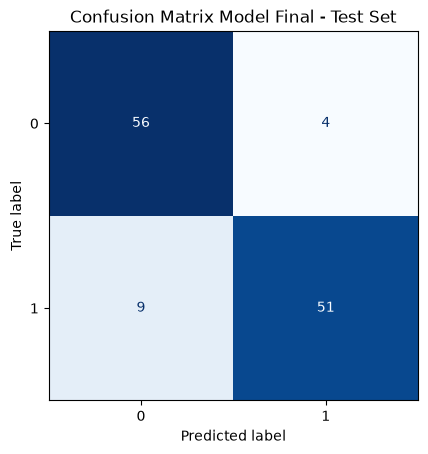

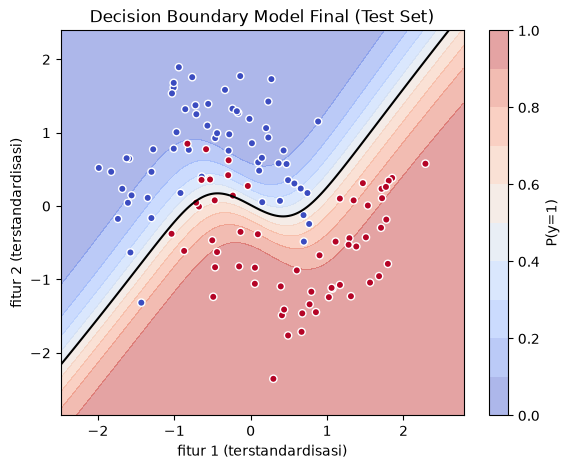

9 baris tersimpan ke M01_123450047_metrics.csv


,run_id,train_loss,val_loss,val_metric,test_metric
0,baseline-relu-8,0.2078,0.2500,0.8833,
1,individu-sigmoid-8,0.2951,0.3410,0.8583,
2,relu-4,0.2753,0.3247,0.8500,
3,relu-16,0.2555,0.2915,0.8667,
4,tanh-4,0.2925,0.3383,0.8583,
5,tanh-16,0.2032,0.2417,0.8917,
6,sigmoid-4,0.2977,0.3430,0.8583,
7,sigmoid-16,0.2919,0.3383,0.8583,
8,final-tanh-16,0.2032,0.2417,0.8917,0.8917


In [22]:
def plot_decision_boundary(model, X_values, y_values, title):
    x0_min, x0_max = X_values[:, 0].min() - 0.5, X_values[:, 0].max() + 0.5
    x1_min, x1_max = X_values[:, 1].min() - 0.5, X_values[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x0_min, x0_max, 220), np.linspace(x1_min, x1_max, 220))
    mesh = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32, device=DEVICE)
    model.eval()
    with torch.no_grad():
        probabilities = torch.sigmoid(model(mesh)).cpu().numpy().reshape(xx.shape)
    fig, ax = plt.subplots(figsize=(6.5, 5))
    contour = ax.contourf(xx, yy, probabilities, levels=np.linspace(0, 1, 11), cmap='coolwarm', alpha=0.45)
    ax.contour(xx, yy, probabilities, levels=[0.5], colors='black', linewidths=1.5)
    ax.scatter(X_values[:, 0], X_values[:, 1], c=y_values, cmap='coolwarm', edgecolor='white', s=28)
    ax.set(title=title, xlabel='fitur 1 (terstandardisasi)', ylabel='fitur 2 (terstandardisasi)')
    fig.colorbar(contour, ax=ax, label='P(y=1)')
    plt.show()

best_row = results.iloc[0]
best_activation = best_row['run_id'].split('-')[0]
best_hidden = int(best_row['model'].split('-')[2])
print('Konfigurasi terbaik dari validation loss:', best_row['run_id'], dict(best_row))

final_model = build_model(best_hidden, best_activation)
final_history, final_runtime = train_model(final_model, epochs=200, learning_rate=0.05, batch_size=32, seed=SEED)
final_history_df = final_history if isinstance(final_history, pd.DataFrame) else pd.DataFrame(final_history)
test_metrics = evaluate(final_model, X_test_t, y_test_t)
print('Evaluasi test SATU KALI:', {'test_loss': round(test_metrics["loss"], 4),
      'test_accuracy': round(test_metrics["accuracy"], 4)})
train_final_loss = float(final_history_df['train_loss'].iloc[-1])
all_rows.append({
    'run_id': f'final-{best_activation}-{best_hidden}', 'module': 'M01', 'student_id': NIM,
    'seed': SEED, 'dataset': 'make_moons', 'split': 'train-val-test',
    'model': f'FNN-2-{best_hidden}-1-{best_activation}', 'optimizer': 'SGD',
    'learning_rate': 0.05, 'batch_size': 32, 'epochs': 200,
    'train_loss': round(train_final_loss, 4), 'val_loss': float(best_row['val_loss']),
    'val_metric': float(best_row['val_metric']),
    'test_metric': round(test_metrics['accuracy'], 4),
    'parameters': count_parameters(final_model), 'trainable_parameters': count_parameters(final_model),
    'runtime_seconds': round(final_runtime, 2), 'device': str(DEVICE),
    'notes': f'test_loss={round(test_metrics["loss"], 4)}; retrain konfigurasi terbaik, test dipakai satu kali',
})

ConfusionMatrixDisplay(confusion_matrix(y_test, test_metrics['predictions'])).plot(cmap='Blues', colorbar=False)
plt.title('Confusion Matrix Model Final - Test Set')
plt.show()
plot_decision_boundary(final_model, X_test_s, y_test, 'Decision Boundary Model Final (Test Set)')

metrics_df = pd.DataFrame(all_rows, columns=METRIC_COLS)
metrics_df.to_csv(f'M01_{NIM}_metrics.csv', index=False)
print(f'{len(metrics_df)} baris tersimpan ke M01_{NIM}_metrics.csv')
display(metrics_df[['run_id', 'train_loss', 'val_loss', 'val_metric', 'test_metric']])

## J. Analisis dan refleksi - 10 poin

Jawab dengan mengacu pada angka dan grafik hasil eksperimen.

1. **Apakah hidden size yang lebih besar selalu menghasilkan validation loss yang lebih rendah?** Tidak selalu. Penambahan jumlah neuron memang meningkatkan kapasitas model, tetapi hasil akhirnya tetap dipengaruhi oleh jenis fungsi aktivasi dan proses optimasi.

2. **Aktivasi mana yang paling stabil pada dua hidden size?** Stabilitas dapat dilihat dari perubahan validation loss ketika hidden size diubah dari 4 menjadi 16. Gunakan hasil pada tabel eksperimen untuk membandingkan perubahan tersebut.

3. **Apakah ada konfigurasi dengan accuracy yang hampir sama tetapi BCE berbeda? Mengapa?** Ada kemungkinan demikian. Accuracy hanya melihat benar atau salah berdasarkan ambang probabilitas, sedangkan BCE juga mempertimbangkan seberapa yakin model terhadap prediksinya. Karena itu, dua model dapat memiliki accuracy yang sama tetapi nilai BCE berbeda.

4. **Di bagian mana decision boundary paling tidak pasti?** Area yang paling tidak pasti berada di sekitar batas dengan probabilitas prediksi mendekati 0,5. Pada area tersebut model belum memiliki keyakinan kuat untuk menentukan kelas.

5. **Apa salah satu keterbatasan eksperimen ini?** Eksperimen menggunakan satu seed dan dataset yang relatif kecil. Oleh karena itu, hasil yang diperoleh dapat berubah apabila seed, ukuran data, optimizer, atau pengaturan training diubah.

6. **Apakah hasil sesuai dengan hipotesis awal?** Bandingkan konfigurasi dengan validation loss terendah pada hasil eksperimen dengan hipotesis awal. Kesimpulan akhir ditentukan berdasarkan hasil pengujian, bukan hanya berdasarkan prediksi awal.


## Checklist pengumpulan - 5 poin reproduksibilitas

- [x] Identitas, seed, versi library, dan device tercantum.
- [x] Forward NumPy-PyTorch memiliki selisih kurang dari $10^{-6}$.
- [x] Enam eksperimen tercatat pada notebook dan CSV.
- [x] Test set hanya digunakan untuk model final.
- [x] Semua grafik memiliki judul, label sumbu, dan legenda/caption.
- [x] Notebook dapat dijalankan dengan **Restart Kernel and Run All**.
- [x] Tidak menggunakan path absolut atau data pribadi.
- [x] Sumber eksternal telah diberi atribusi jika digunakan.

### Pernyataan orisinalitas

Saya menyatakan bahwa kode, eksperimen, visualisasi, dan analisis pada notebook ini merupakan pekerjaan individual saya.

**Nama:** Benget Sidabutar  
**NIM:** 123450047  
**Tanggal:** 2026-09-21
